In [1]:
import pandas as pd
orders_df= pd.read_csv("store_orders.csv")
customers_df= pd.read_csv("store_customers.csv")

import sqlite3
con = sqlite3.connect("store.db")

orders_df.to_sql("orders", con, index=False, if_exists="replace")
customers_df.to_sql("customers", con, index=False, if_exists="replace")
pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)

,name
0,orders
1,customers


In [2]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [3]:
pd.read_sql("""
SELECT *
FROM orders
WHERE amount > 100
ORDER BY amount DESC
""", con)

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


In [4]:
pd.read_sql("""
SELECT category, COUNT(*) AS n, AVG(amount) AS avg_amount 
FROM orders 
GROUP BY category 
ORDER BY avg_amount DESC
""",con)

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


The category which earns the most is electronics at 60 per order

In [5]:
city_spend = pd.read_sql("""
SELECT c.city, SUM(o.amount) AS total_spend
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC
""", con)
city_spend

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


In [6]:
pd.read_sql("""
SELECT COUNT(*) AS joined_rows
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
""", con)

,joined_rows
0,195


In [7]:
len(orders_df)

200

The 5 missing orders are due to 5 entries with customer ID that aren't corresponding to any customer. Therefore when it joined, it excluded the 5 entries.

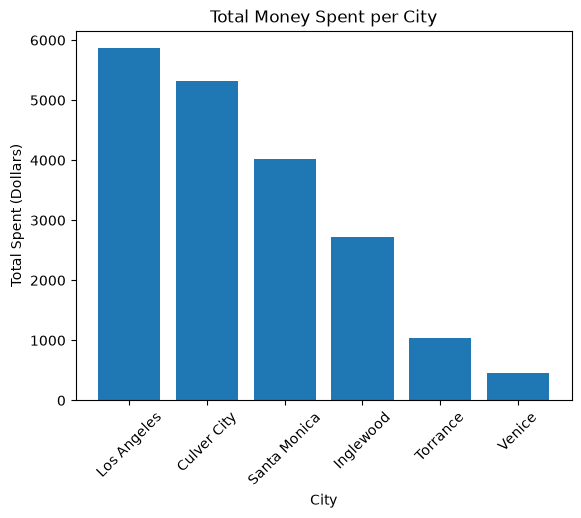

In [8]:
import matplotlib.pyplot as plt
plt.bar(city_spend["city"], city_spend["total_spend"])
plt.title("Total Money Spent per City")
plt.xlabel("City")
plt.ylabel("Total Spent (Dollars)")
plt.xticks(rotation=45)
plt.show()

Which product was ordered the least?

In [9]:
pd.read_sql( """
SELECT product, COUNT(*) AS total_orders
FROM orders
GROUP BY product
ORDER BY total_orders ASC
LIMIT 1
""",con)

,product,total_orders
0,desk,10


Desks were the least ordered item with a total of 10 total orders

Using group data instead of personalized data would assist in hiding customers personal data for public use. Removing names and customer ID numbers when disclosing individual data would also help if necessary.

Repo Address: https://github.com/KyeSPu/cs82a-portfolio